# Alfido Tech Internship — Task 1: Customer Behavior Analysis

**Dataset:** `ecommerce_customer_data_custom_ratios.csv.zip`  
**Tools:** Python, Pandas, NumPy, Matplotlib, Google Colab

Run cells from top to bottom. Upload the original ZIP when prompted. This notebook analyzes customer purchases, creates RFM-based customer segments, visualizes purchase and retention patterns, and exports supporting CSV files and charts.

**Privacy:** The source includes customer names. This notebook excludes names from analysis outputs and does not export the raw source dataset.

## 1. Install/import libraries

In [1]:
import os, zipfile, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
os.makedirs("charts", exist_ok=True)
print("Libraries ready.")

Libraries ready.


## 2. Upload and load the original dataset

In [3]:
uploaded = files.upload()  # Choose ecommerce_customer_data_custom_ratios.csv.zip
uploaded_names = list(uploaded.keys())
if not uploaded_names:
    raise FileNotFoundError("No file uploaded. Upload the original dataset ZIP.")

source = uploaded_names[0]
if source.lower().endswith(".zip"):
    with zipfile.ZipFile(source) as zf:
        csv_names = [n for n in zf.namelist() if n.lower().endswith(".csv")]
        if not csv_names:
            raise FileNotFoundError("The ZIP does not contain a CSV file.")
        with zf.open(csv_names[0]) as f:
            df_raw = pd.read_csv(f)
elif source.lower().endswith(".csv"):
    df_raw = pd.read_csv(source)
else:
    raise ValueError("Please upload a .zip or .csv file.")

print("Dataset shape:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())
display(df_raw.head())

Saving ecommerce_customer_data_custom_ratios.csv (1).zip to ecommerce_customer_data_custom_ratios.csv (1).zip
Dataset shape: (250000, 13)
Columns: ['Customer ID', 'Purchase Date', 'Product Category', 'Product Price', 'Quantity', 'Total Purchase Amount', 'Payment Method', 'Customer Age', 'Returns', 'Customer Name', 'Age', 'Gender', 'Churn']


,Customer ID,Purchase Date,Product Category,Product Price,Quantity,Total Purchase Amount,Payment Method,Customer Age,Returns,Customer Name,Age,Gender,Churn
0,46251,2020-09-08 09:38:32,Electronics,12,3,740,Credit Card,37,0.0,Christine Hernandez,37,Male,0
1,46251,2022-03-05 12:56:35,Home,468,4,2739,PayPal,37,0.0,Christine Hernandez,37,Male,0
2,46251,2022-05-23 18:18:01,Home,288,2,3196,PayPal,37,0.0,Christine Hernandez,37,Male,0
3,46251,2020-11-12 13:13:29,Clothing,196,1,3509,PayPal,37,0.0,Christine Hernandez,37,Male,0
4,13593,2020-11-27 17:55:11,Home,449,1,3452,Credit Card,49,0.0,James Grant,49,Female,1


## 3. Inspect data quality and summary statistics

In [4]:
print("Rows and columns:", df_raw.shape)
print("Duplicate rows:", df_raw.duplicated().sum())
print("Data types:")
display(df_raw.dtypes.to_frame("Data type"))
print("Missing values:")
display(df_raw.isna().sum().to_frame("Missing count"))
numeric_cols = ["Product Price", "Quantity", "Total Purchase Amount", "Customer Age", "Age"]
available_numeric = [c for c in numeric_cols if c in df_raw.columns]
print("Mean:")
display(df_raw[available_numeric].mean())
print("Median:")
display(df_raw[available_numeric].median())
print("Mode (selected categorical columns):")
cat_cols = [c for c in ["Product Category", "Payment Method", "Gender"] if c in df_raw.columns]
display(df_raw[cat_cols].mode())
print("Descriptive statistics:")
display(df_raw.describe(include="all").T)

Rows and columns: (250000, 13)
Duplicate rows: 0
Data types:


,Data type
Customer ID,int64
Purchase Date,object
Product Category,object
Product Price,int64
Quantity,int64
Total Purchase Amount,int64
Payment Method,object
Customer Age,int64
Returns,float64
Customer Name,object


Missing values:


,Missing count
Customer ID,0
Purchase Date,0
Product Category,0
Product Price,0
Quantity,0
Total Purchase Amount,0
Payment Method,0
Customer Age,0
Returns,47596
Customer Name,0


Mean:


...

,0
Product Price,255.0
Quantity,3.0
Total Purchase Amount,2724.0
Customer Age,44.0
Age,44.0


Mode (selected categorical columns):


,Product Category,Payment Method,Gender
0,Clothing,Credit Card,Female


Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer ID,250000.0,NaN,NaN,NaN,25004.03624,14428.27959,1.0,12497.75,25018.0,37506.0,50000.0
Purchase Date,250000,249736,2022-05-08 12:58:55,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product Category,250000,4,Clothing,75052,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product Price,250000.0,NaN,NaN,NaN,254.659512,141.568577,10.0,132.0,255.0,377.0,500.0
Quantity,250000.0,NaN,NaN,NaN,2.998896,1.414694,1.0,2.0,3.0,4.0,5.0
Total Purchase Amount,250000.0,NaN,NaN,NaN,2725.370732,1442.933565,100.0,1477.0,2724.0,3974.0,5350.0
Payment Method,250000,4,Credit Card,100486,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Age,250000.0,NaN,NaN,NaN,43.940528,15.350246,18.0,31.0,44.0,57.0,70.0
Returns,202404.0,NaN,NaN,NaN,0.497861,0.499997,0.0,0.0,0.0,1.0,1.0
Customer Name,250000,39920,Michael Smith,107,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Clean data and engineer features
Missing `Returns` values remain unknown; they are not assumed to mean 'not returned'. Customer names are excluded from exported analysis tables.

In [5]:
df = df_raw.copy()
df.columns = df.columns.str.strip()
df = df.drop_duplicates().copy()

df["Purchase Date"] = pd.to_datetime(df["Purchase Date"], errors="coerce")
for col in ["Customer ID", "Product Price", "Quantity", "Total Purchase Amount", "Customer Age", "Age", "Churn", "Returns"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Essential fields required for transaction analysis
df = df.dropna(subset=["Customer ID", "Purchase Date", "Total Purchase Amount"]).copy()
df["Customer ID"] = df["Customer ID"].astype("int64")
if "Churn" in df.columns:
    df["Churn"] = df["Churn"].fillna(0).astype("int64")

df["Return Status"] = df["Returns"].map({0: "No return", 1: "Returned"}).fillna("Unknown")
df["Purchase Month"] = df["Purchase Date"].dt.to_period("M").astype(str)
df["Purchase Year"] = df["Purchase Date"].dt.year
df["Customer Name"] = df["Customer Name"] if "Customer Name" in df.columns else np.nan

print("Original rows:", len(df_raw))
print("Rows after duplicate/essential-field cleaning:", len(df))
print("Unique customers:", df["Customer ID"].nunique())
print("Missing Returns still marked unknown:", int(df["Returns"].isna().sum()))
display(df.head())

Original rows: 250000
Rows after duplicate/essential-field cleaning: 250000
Unique customers: 49673
Missing Returns still marked unknown: 47596


,Customer ID,Purchase Date,Product Category,Product Price,Quantity,Total Purchase Amount,Payment Method,Customer Age,Returns,Customer Name,Age,Gender,Churn,Return Status,Purchase Month,Purchase Year
0,46251,2020-09-08 09:38:32,Electronics,12,3,740,Credit Card,37,0.0,Christine Hernandez,37,Male,0,No return,2020-09,2020
1,46251,2022-03-05 12:56:35,Home,468,4,2739,PayPal,37,0.0,Christine Hernandez,37,Male,0,No return,2022-03,2022
2,46251,2022-05-23 18:18:01,Home,288,2,3196,PayPal,37,0.0,Christine Hernandez,37,Male,0,No return,2022-05,2022
3,46251,2020-11-12 13:13:29,Clothing,196,1,3509,PayPal,37,0.0,Christine Hernandez,37,Male,0,No return,2020-11,2020
4,13593,2020-11-27 17:55:11,Home,449,1,3452,Credit Card,49,0.0,James Grant,49,Female,1,No return,2020-11,2020


## 5. RFM customer segmentation
Recency is measured against one day after the latest transaction in the dataset. Frequency counts transactions/rows, and Monetary sums `Total Purchase Amount`.

In [6]:
analysis_date = df["Purchase Date"].max().normalize() + pd.Timedelta(days=1)
rfm = df.groupby("Customer ID").agg(
    Last_Purchase=("Purchase Date", "max"),
    Frequency=("Purchase Date", "count"),
    Monetary=("Total Purchase Amount", "sum")
).reset_index()
rfm["Recency"] = (analysis_date - rfm["Last_Purchase"].dt.normalize()).dt.days

# Rank-based scores work even when values have many ties
rfm["R_Score"] = pd.qcut(rfm["Recency"].rank(method="first"), 5, labels=[5,4,3,2,1]).astype(int)
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)
rfm["M_Score"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)

def segment_customer(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"
    if row["R_Score"] >= 3 and row["F_Score"] >= 4:
        return "Loyal / Active"
    if row["R_Score"] >= 4 and row["F_Score"] <= 2:
        return "Recent / Promising"
    if row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"
    return "Needs Attention"

rfm["Segment"] = rfm.apply(segment_customer, axis=1)
segment_summary = rfm.groupby("Segment").agg(
    Customers=("Customer ID", "nunique"),
    Avg_Recency_Days=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Monetary=("Monetary", "sum")
).reset_index().sort_values("Customers", ascending=False)
display(segment_summary.round(2))
display(rfm.head())

,Segment,Customers,Avg_Recency_Days,Avg_Frequency,Avg_Monetary,Total_Monetary
3,Needs Attention,20602,367.94,3.45,9418.66,194043164
0,At Risk,8744,411.35,5.94,16158.90,141293406
1,Champions,8690,61.35,7.65,21789.01,189346466
2,Loyal / Active,6264,149.44,6.88,17459.77,109368025
4,Recent / Promising,5373,67.62,3.24,8801.72,47291622


,Customer ID,Last_Purchase,Frequency,Monetary,Recency,R_Score,F_Score,M_Score,Segment
0,1,2023-07-19 19:09:20,1,3491,59,5,1,1,Recent / Promising
1,2,2022-11-21 06:48:05,3,7988,299,2,1,2,Needs Attention
2,3,2023-06-18 12:31:42,8,22587,90,4,5,5,Champions
3,4,2023-05-12 10:50:24,4,8715,127,4,2,2,Recent / Promising
4,5,2023-03-28 13:30:55,8,12524,172,3,5,3,Loyal / Active


## 6. Purchase pattern visualizations

,Product Category,Transactions,Total_Purchase_Amount,Average_Purchase_Amount
0,Books,74912,204939601,2735.74
1,Clothing,75052,204532405,2725.21
2,Electronics,50185,136599467,2721.92
3,Home,49851,135271210,2713.51


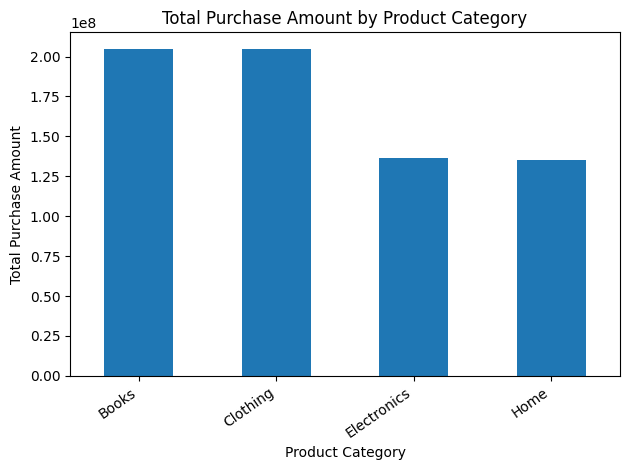

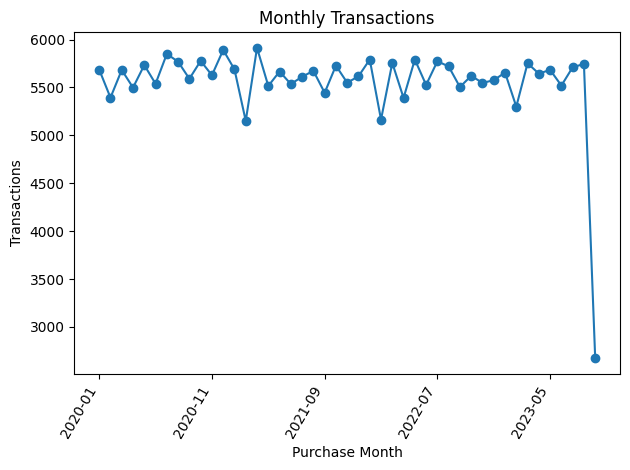

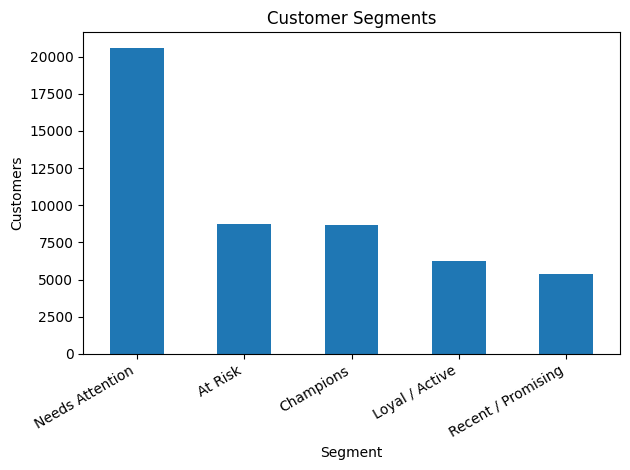

In [7]:
category_summary = df.groupby("Product Category", dropna=False).agg(
    Transactions=("Customer ID", "size"),
    Total_Purchase_Amount=("Total Purchase Amount", "sum"),
    Average_Purchase_Amount=("Total Purchase Amount", "mean")
).reset_index().sort_values("Total_Purchase_Amount", ascending=False)
display(category_summary.round(2))

ax = category_summary.plot(kind="bar", x="Product Category", y="Total_Purchase_Amount", legend=False)
ax.set_title("Total Purchase Amount by Product Category")
ax.set_xlabel("Product Category"); ax.set_ylabel("Total Purchase Amount")
plt.xticks(rotation=35, ha="right"); plt.tight_layout()
plt.savefig("charts/sales_by_category.png", dpi=150); plt.show()

monthly = df.groupby("Purchase Month").agg(
    Transactions=("Customer ID", "size"),
    Unique_Customers=("Customer ID", "nunique"),
    Total_Purchase_Amount=("Total Purchase Amount", "sum")
).reset_index()
ax = monthly.plot(x="Purchase Month", y="Transactions", marker="o", legend=False)
ax.set_title("Monthly Transactions"); ax.set_xlabel("Purchase Month"); ax.set_ylabel("Transactions")
plt.xticks(rotation=60, ha="right"); plt.tight_layout()
plt.savefig("charts/monthly_transactions.png", dpi=150); plt.show()

seg_counts = rfm["Segment"].value_counts()
ax = seg_counts.plot(kind="bar")
ax.set_title("Customer Segments"); ax.set_xlabel("Segment"); ax.set_ylabel("Customers")
plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig("charts/customer_segments.png", dpi=150); plt.show()

## 7. Retention, churn and returns

,Purchase Month,Unique_Customers,Repeat_Customers,Repeat_Customer_Share
33,2022-10,5331,5196,0.975
34,2022-11,5244,5119,0.976
35,2022-12,5281,5204,0.985
36,2023-01,5355,5252,0.981
37,2023-02,5032,4942,0.982
38,2023-03,5454,5385,0.987
39,2023-04,5344,5276,0.987
40,2023-05,5389,5329,0.989
41,2023-06,5214,5163,0.990
42,2023-07,5388,5334,0.990


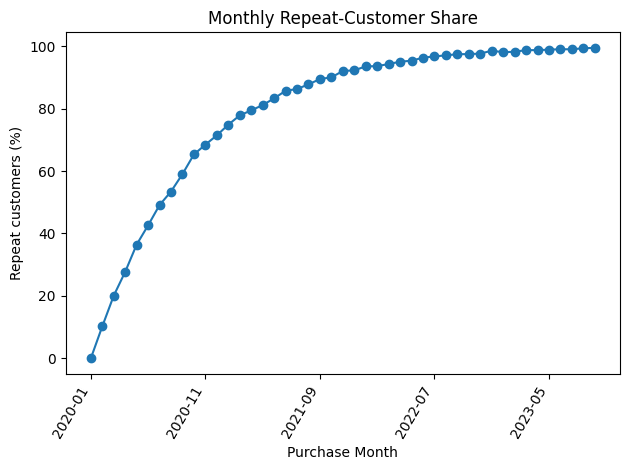

,Transaction rows
Churn,
0,200126
1,49874


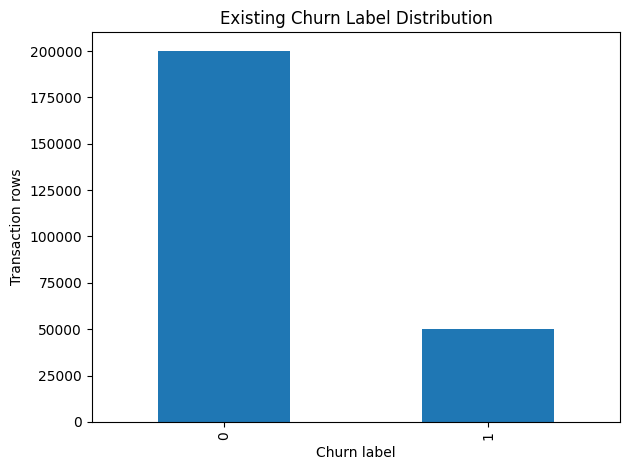

,Transaction rows
Return Status,
No return,101635
Returned,100769
Unknown,47596


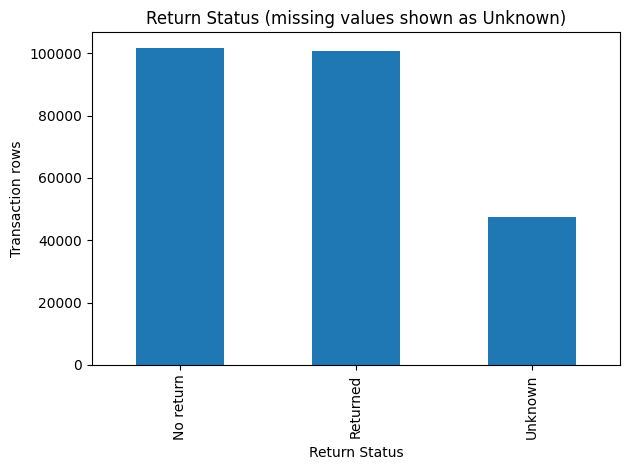

In [8]:
# Monthly repeat-customer share: customers in a month who also purchased in an earlier month.
monthly_customers = df[["Customer ID", "Purchase Month"]].drop_duplicates().copy()
monthly_customers["Month_Period"] = pd.PeriodIndex(monthly_customers["Purchase Month"], freq="M")
monthly_customers = monthly_customers.sort_values(["Customer ID", "Month_Period"])
monthly_customers["Previous_Month_Purchase"] = monthly_customers.groupby("Customer ID")["Month_Period"].transform(lambda s: s > s.min())
repeat_trend = monthly_customers.groupby("Purchase Month").agg(
    Unique_Customers=("Customer ID", "nunique"),
    Repeat_Customers=("Previous_Month_Purchase", "sum")
).reset_index()
repeat_trend["Repeat_Customer_Share"] = np.where(
    repeat_trend["Unique_Customers"] > 0,
    repeat_trend["Repeat_Customers"] / repeat_trend["Unique_Customers"], 0
)
display(repeat_trend.tail(12).round(3))

ax = (repeat_trend.set_index("Purchase Month")["Repeat_Customer_Share"] * 100).plot(marker="o")
ax.set_title("Monthly Repeat-Customer Share"); ax.set_xlabel("Purchase Month"); ax.set_ylabel("Repeat customers (%)")
plt.xticks(rotation=60, ha="right"); plt.tight_layout()
plt.savefig("charts/monthly_repeat_customer_share.png", dpi=150); plt.show()

if "Churn" in df.columns:
    churn_summary = df["Churn"].value_counts(dropna=False).sort_index()
    display(churn_summary.to_frame("Transaction rows"))
    ax = churn_summary.plot(kind="bar")
    ax.set_title("Existing Churn Label Distribution"); ax.set_xlabel("Churn label"); ax.set_ylabel("Transaction rows")
    plt.tight_layout(); plt.savefig("charts/churn_distribution.png", dpi=150); plt.show()

return_summary = df["Return Status"].value_counts()
display(return_summary.to_frame("Transaction rows"))
ax = return_summary.plot(kind="bar")
ax.set_title("Return Status (missing values shown as Unknown)")
ax.set_xlabel("Return Status"); ax.set_ylabel("Transaction rows")
plt.tight_layout(); plt.savefig("charts/return_status.png", dpi=150); plt.show()

## 8. Five actionable recommendations
These are hypotheses to validate against the tables and charts above, not guaranteed causal findings.

In [9]:
recommendations = [
    "Reward Champions with loyalty benefits and early access; track repeat purchases and spend after the campaign.",
    "Run a targeted win-back campaign for At Risk customers; compare reactivation against a holdout group.",
    "Offer a relevant second-purchase incentive to Recent / Promising customers to encourage habit formation.",
    "Use category-level sales results to prioritize merchandising and test bundles for complementary products.",
    "Improve return-status completeness and maintain consistent customer identifiers so retention and return reporting is more reliable."
]
for i, item in enumerate(recommendations, 1):
    print(f"{i}. {item}")

1. Reward Champions with loyalty benefits and early access; track repeat purchases and spend after the campaign.
2. Run a targeted win-back campaign for At Risk customers; compare reactivation against a holdout group.
3. Offer a relevant second-purchase incentive to Recent / Promising customers to encourage habit formation.
4. Use category-level sales results to prioritize merchandising and test bundles for complementary products.
5. Improve return-status completeness and maintain consistent customer identifiers so retention and return reporting is more reliable.


## 9. Export analysis outputs
Only analysis tables are exported; customer names are excluded.

In [10]:
# Export cleaned transactions without direct customer names
clean_export = df.drop(columns=["Customer Name"], errors="ignore")
clean_export.to_csv("cleaned_customer_transactions.csv", index=False)
rfm.to_csv("customer_rfm_segments.csv", index=False)
segment_summary.to_csv("customer_segment_summary.csv", index=False)
category_summary.to_csv("category_summary.csv", index=False)
monthly.to_csv("monthly_purchase_summary.csv", index=False)
repeat_trend.to_csv("monthly_repeat_customer_trend.csv", index=False)

print("Exported files:")
for f in [
    "cleaned_customer_transactions.csv",
    "customer_rfm_segments.csv",
    "customer_segment_summary.csv",
    "category_summary.csv",
    "monthly_purchase_summary.csv",
    "monthly_repeat_customer_trend.csv"
]:
    print("-", f, os.path.getsize(f), "bytes")
print("Charts saved in charts/ folder.")

Exported files:
- cleaned_customer_transactions.csv 23151636 bytes
- customer_rfm_segments.csv 2826684 bytes
- customer_segment_summary.csv 493 bytes
- category_summary.csv 248 bytes
- monthly_purchase_summary.csv 1281 bytes
- monthly_repeat_customer_trend.csv 1715 bytes
Charts saved in charts/ folder.
